File: waechtler_homework_3_dataset_demo.ipynb

Author: Emmett C. Waechtler

Course: ISTA 421 - Introduction to Machine Learning

Professor: Salena Torres

In [19]:
# Load and cache the query as done in the linear regression notebook
import os
import pandas as pd

URL = ("https://tomcat.ivilab.org/tomcat/affective_task_event.csv"
       "?_stream=on&_size=max")
CACHE = "data/affective_task_event.csv"

os.makedirs("data", exist_ok=True)
if os.path.exists(CACHE):
    df = pd.read_csv(CACHE)
else:
    df = pd.read_csv(URL)
    df.to_csv(CACHE, index=False)
    # download once, reuse afterwards

df = df[["arousal_score", "valence_score"]].dropna()
print(df.shape)
df.describe()

(2373, 2)


,arousal_score,valence_score
count,2373.000000,2373.000000
mean,0.015171,0.274336
std,1.330574,1.245296
min,-2.000000,-2.000000
25%,-1.000000,0.000000
50%,0.000000,0.000000
75%,1.000000,1.000000
max,2.000000,2.000000


DATASET DEMONSTRATION

Common Problems with Linear Regression on a Dataset:

1. Non-linearity of the response-predictor relationships.
2. Correlation of error terms.
3. Non-constant variance of error terms.
4. Outliers.
5. High leverage points.
6. Collinearity among the predictor values

(ISLP Chapter 3 page 100)

I will be checking the ToMCAT dataset for these problems.

Problem 1: Non-linearity of the response-predictor relationships

Check/Solution: plot the residuals, $e_i = y_i - \hat{y}_i$, against the predictor $x_i$.

If a pattern is observed, it indicates non-linearity, and our assumptions become suspect.

To address this, we can consider transforming the predictor variables using a non-linear function (e.g., log X, $\sqrt{X}$, $X^2$) to better capture the relationship.

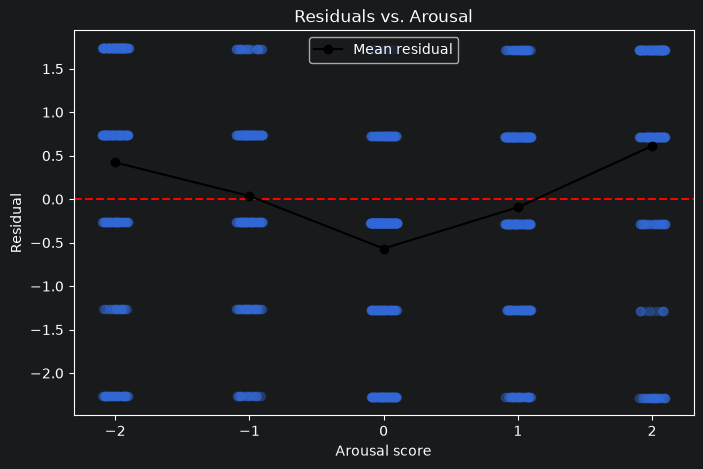

Linear R^2: 0.0000 | Quadratic R^2: 0.1106


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

x = df["arousal_score"]
y = df["valence_score"]

X = sm.add_constant(x)
model = sm.OLS(y, X).fit()
fitted = model.fittedvalues
resid = model.resid

# Residuals vs. predictor (jittered because arousal only takes integer values between -2 and 2)
jitter = np.random.uniform(-0.1, 0.1, size=len(x))
plt.figure(figsize=(8, 5))
plt.scatter(x + jitter, resid, alpha=0.2)
plt.axhline(0, color="red", linestyle="--")

# Mean residual at each arousal level; a pattern here suggests non-linearity
mean_resid = resid.groupby(x).mean()
plt.plot(mean_resid.index, mean_resid.values, "o-", color="black", label="Mean residual")
plt.xlabel("Arousal score")
plt.ylabel("Residual")
plt.title("Residuals vs. Arousal")
plt.legend()
plt.show()

# The resulting plot looks like a grid, so we try a non-linear transformation of the predictor (X^2) and compare R^2
X_quad = sm.add_constant(pd.DataFrame({"x": x, "x2": x**2}))
model_quad = sm.OLS(y, X_quad).fit()
print(f"Linear R^2: {model.rsquared:.4f} | Quadratic R^2: {model_quad.rsquared:.4f}")

#Problem 2: Correlation of error terms may lead to an unwarranted sense of confidence in our model.

Check/Solution: Create residual plots, and check for 'tracking' of residuals. Higher tracking indicates greater correlation of error terms. If no pattern is observed, our assumptions are likely valid.


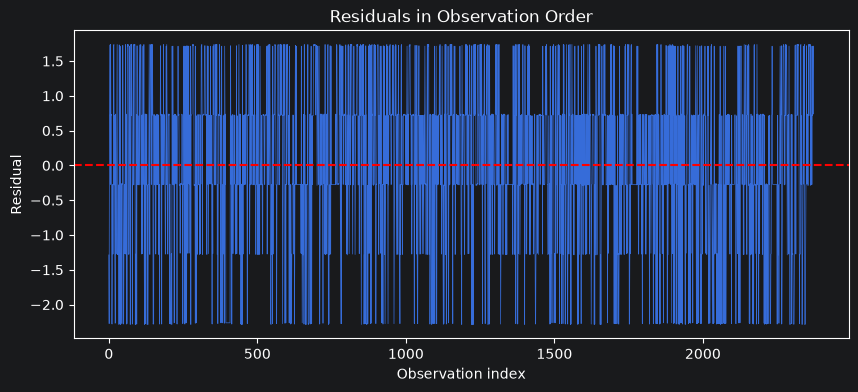

In [21]:
# Residuals in observation order; look for similar residuals between neighbors (tracking).
plt.figure(figsize=(10, 4))
plt.plot(resid.values, linewidth=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Observation index")
plt.ylabel("Residual")
plt.title("Residuals in Observation Order")
plt.show()


Problem 3: Non-constant variance of error terms (Heteroscedasticity).

Check/Solution: Plot residuals against fitted values. If the spread of residuals increases or decreases (funnels) with fitted values, it indicates heteroscedasticity. To address this, we can apply a concave transformation (e.g., log Y, $\sqrt(Y)$ to stabilize variance.

In [22]:
# Example Code:

Problem 4: Outliers can disproportionately influence the regression model.

Check/Solution: Plot studentized residuals, by dividing each residual $e_i$ by its estimated standard error. Observations with studentized residuals greater than 3 in absolute value are considered potential outliers. We can investigate these points further and decide whether to remove them or not.

In [23]:
#Example Code:


Problem 5: High leverage points have unusual values for the predictor variables.

Check/Solution: Calculate leverage statistics, $h_i$, for each observation. Observations with leverage greatly exceeding $\frac{(p + 1)}{n}$, then we may suspect the point has high leverage. Since high leverage points can influence the regression line significantly, we should seek to remove them if appropriate. Plotting Y vs. X, X1 vs. X2, or Studentized Residuals vs. Leverage can help identify these points. (include equation for h1)

In [24]:
# Example Code:


Problem 6: Collinearity among the predictor variables.

Check/Solution: For simple collinearity, we can compute the correlation matrix of the predictors. For multicollinearity, we can compute the Variance Inflation Factor (VIF) for each predictor. $$\mathrm{VIF}(\hat{\beta}_j) = \frac{1}{1 - R^2_{X_j \mid X_{-j}}}$$ A VIF value exceeding 5 or 10 indicates a problematic amount of collinearity. To address collinearity, we can consider removing or combining correlated predictors.

In [25]:
# Example Code:
